# Analysis 2 · Uncertainty: Do the models know when they are unsure?

This notebook looks at the three ensembles: the physics-based IFS ENS, the AI model GenCast and the hybrid NeuralGCM ENS. All ensembles are compared with 50 members.

**How to use this notebook:** All analyses are ready. Run all cells (or read the exported version).
Every figure has a number. When you check a claim, name the figure that supports or contradicts it.

Data: WeatherBench 2, January 2020, 64×32 grid (about 600 km), ERA5 as reference.
Dashed lines = physics-based models (HRES, IFS ENS). Solid lines = AI or hybrid models.

| Figure | What it shows |
|---|---|
| **2.1** | Ensemble quality (CRPS) over lead time |
| **2.2** | Calibration: spread-skill ratio |
| **2.3** | Rank histograms: honest or overconfident? |
| **2.4** | How many members are needed? |
| **2.5** | Ensemble mean versus single forecasts |
| **2.6** | One city: two ensembles |
| **2.7** | Where the ensembles are unsure, and where they are wrong |

In [1]:
from wb2_helpers import *
CITY = 'Hannover'            # used for the city figures (see CITIES in wb2_helpers.py)
MAP_DATE = '2020-01-25T00'   # valid time for maps (between 2020-01-08 and 2020-02-07)
col = lambda m: COLORS[m.replace(' (mean)', '').replace(' (member)', '')]
available()

,HRES,GraphCast,Pangu,NeuralGCM,IFS ENS,GenCast,NeuralGCM ENS
2-m temperature (K),✅,✅,✅,—,✅,✅,—
10-m wind speed (m/s),✅,✅,✅,—,✅,✅,—
Z500 (m²/s²),✅,✅,✅,✅,✅,✅,✅


### Figure 2.1 · Ensemble quality over lead time

*How to read:* CRPS measures the error of the whole ensemble distribution, lower is better. Do not compare CRPS values with the RMSE values in Analysis 1.

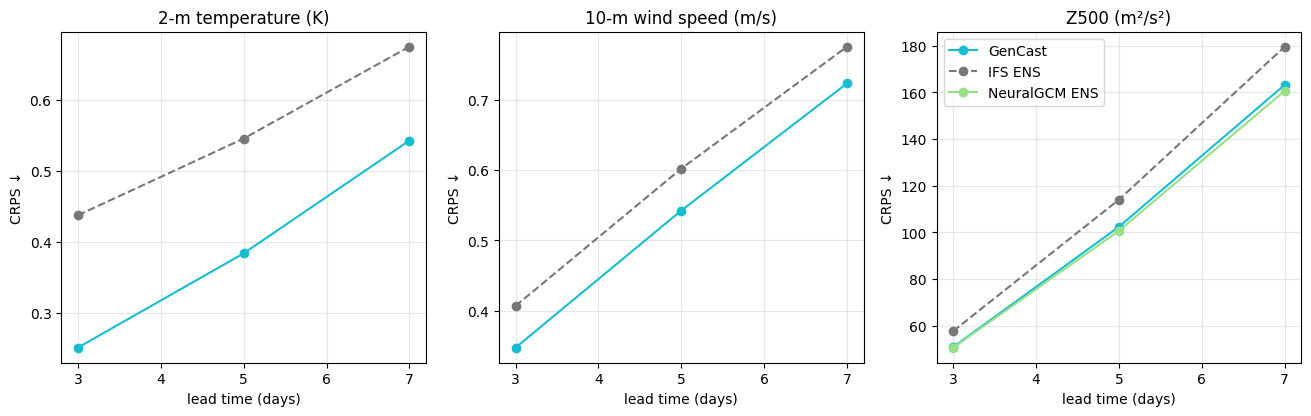

model                GenCast  IFS ENS  NeuralGCM ENS
var            days                                 
10m_wind_speed 3       0.348    0.407            NaN
               5       0.542    0.602            NaN
               7       0.723    0.775            NaN
2m_temperature 3       0.250    0.437            NaN
               5       0.384    0.546            NaN
               7       0.543    0.675            NaN
geopotential   3      50.843   57.684         50.584
               5     102.373  113.996        100.672
               7     163.223  179.565        160.606

In [2]:
rows = []
for var in VARS:
    for d, l in LEADS.items():
        for m, (n, md) in ENS.items():
            fc, tr = ens_forecast(m, var, l, 50)
            if fc is not None:
                rows.append({'model': m, 'var': var, 'days': d, 'crps': crps(fc, tr, md), 'spread_skill': spread_skill(fc, tr, md)})
ens = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
for a, var in zip(axs, VARS):
    for m, s in ens[ens['var'] == var].groupby('model'):
        a.plot(s.days, s.crps, 'o', ls=STYLE[m], color=COLORS[m], label=m)
    a.set_title(VARS[var]); a.set_xlabel('lead time (days)'); a.set_ylabel('CRPS ↓'); a.grid(alpha=.3)
axs[-1].legend()
save(fig, '2.1')
ens.pivot_table(index=['var', 'days'], columns='model', values='crps').round(3)

### Figure 2.2 · Calibration

*How to read:* Spread-skill ratio: 1 = the spread of the ensemble matches its actual error. Below 1 = overconfident (too little spread), above 1 = too cautious.

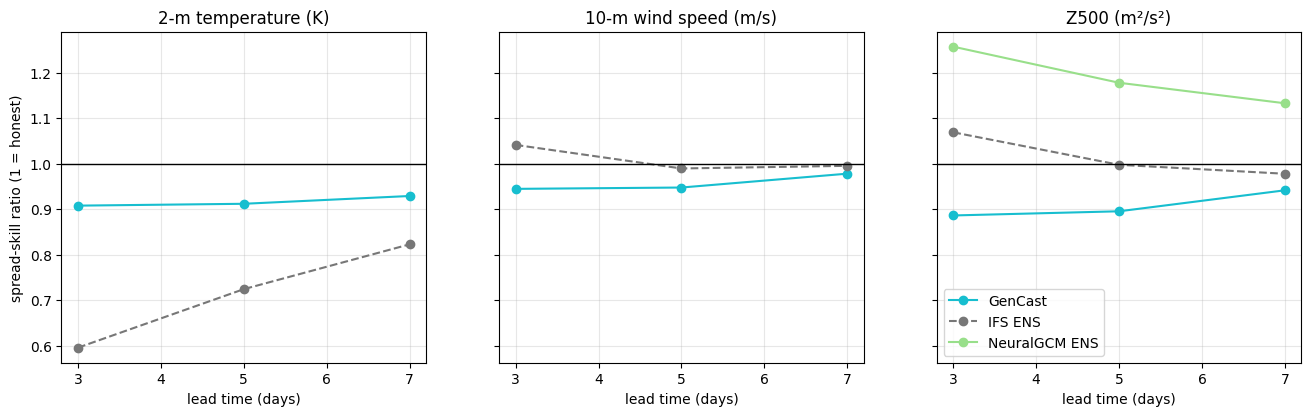

model                GenCast  IFS ENS  NeuralGCM ENS
var            days                                 
10m_wind_speed 3       0.945    1.041            NaN
               5       0.947    0.989            NaN
               7       0.978    0.995            NaN
2m_temperature 3       0.908    0.596            NaN
               5       0.912    0.724            NaN
               7       0.929    0.823            NaN
geopotential   3       0.886    1.069          1.257
               5       0.895    0.997          1.178
               7       0.941    0.978          1.133

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for a, var in zip(axs, VARS):
    for m, s in ens[ens['var'] == var].groupby('model'):
        a.plot(s.days, s.spread_skill, 'o', ls=STYLE[m], color=COLORS[m], label=m)
    a.axhline(1, color='k', lw=1); a.set_title(VARS[var]); a.set_xlabel('lead time (days)'); a.grid(alpha=.3)
axs[0].set_ylabel('spread-skill ratio (1 = honest)'); axs[-1].legend()
save(fig, '2.2')
ens.pivot_table(index=['var', 'days'], columns='model', values='spread_skill').round(3)

### Figure 2.3 · Rank histograms

*How to read:* Where does reality fall among the 50 sorted members? Flat = honest. U-shape = reality often outside all members (overconfident). Tilted = systematic bias. Dashed line = perfectly calibrated.

Ideal share of reality outside all 50 members: 3.9%


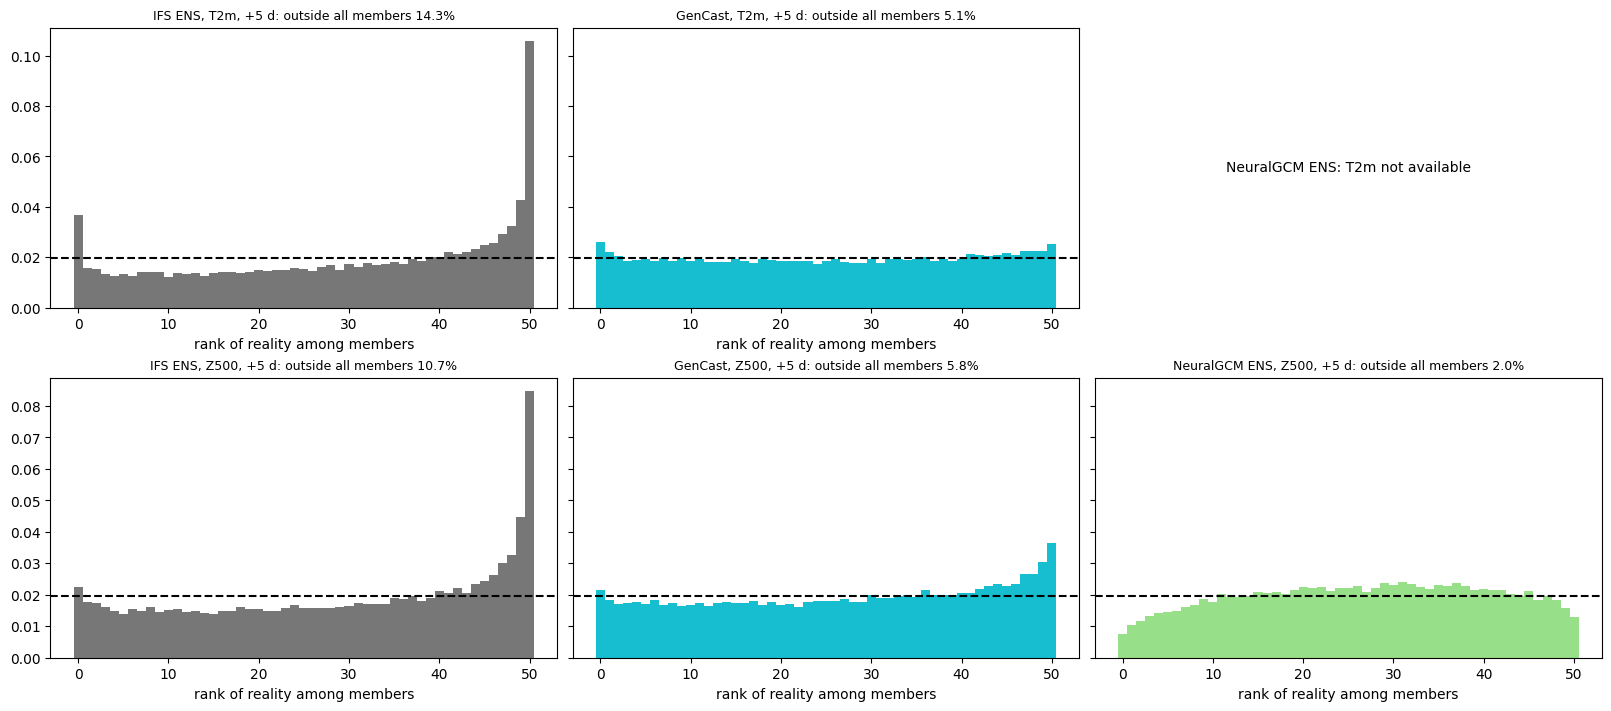

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(16, 7), sharey='row', layout='constrained')
outside = {}
for row, var in enumerate(['2m_temperature', 'geopotential']):
    for a, (m, (n, md)) in zip(axs[row], ENS.items()):
        fc, tr = ens_forecast(m, var, LEADS[5], 50)
        if fc is None:
            a.text(.5, .5, f'{m}: {SHORT[var]} not available', ha='center', va='center', transform=a.transAxes); a.set_axis_off()
            continue
        rh = rank_histogram(fc, tr, md); outside[(m, SHORT[var])] = rh[0] + rh[-1]
        a.bar(range(len(rh)), rh, width=1, color=COLORS[m]); a.axhline(1 / len(rh), color='k', ls='--')
        a.set_title(f'{m}, {SHORT[var]}, +5 d: outside all members {rh[0] + rh[-1]:.1%}', fontsize=9)
        a.set_xlabel('rank of reality among members')
print(f'Ideal share of reality outside all 50 members: {2 / 51:.1%}')
save(fig, '2.3')

### Figure 2.4 · How many members are needed?

*How to read:* CRPS of random sub-ensembles of different size, 2-m temperature at day 5. Left: standard CRPS. Right: "fair" CRPS, which removes the built-in penalty of the score for small ensembles.

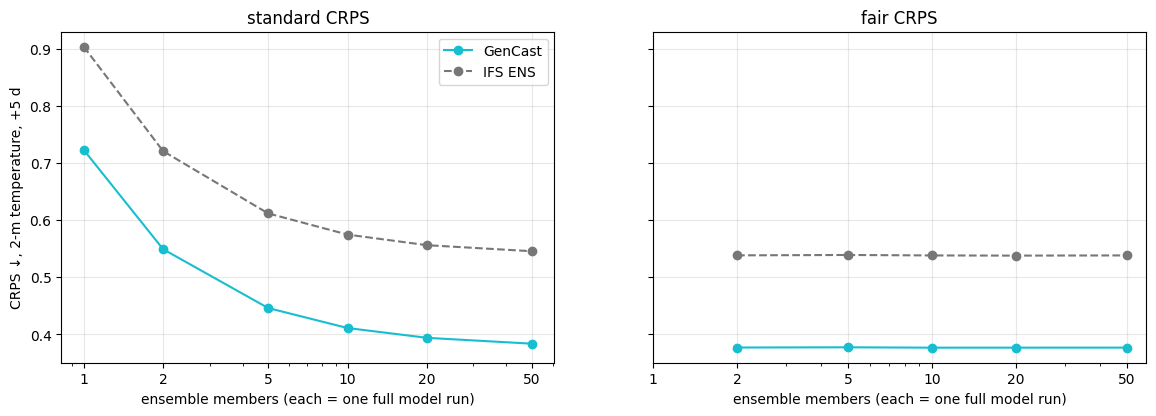

fair CRPS         standard CRPS        
model     GenCast IFS ENS       GenCast IFS ENS
members                                        
1             NaN     NaN         0.723   0.904
2           0.377   0.538         0.549   0.721
5           0.377   0.539         0.446   0.612
10          0.377   0.538         0.411   0.575
20          0.377   0.538         0.394   0.556
50          0.377   0.538         0.384   0.546

In [5]:
SIZES = [1, 2, 5, 10, 20, 50]
rows = []
for m in ['IFS ENS', 'GenCast']:
    n, md = ENS[m]
    fc, tr = ens_forecast(m, '2m_temperature', LEADS[5])
    for k in SIZES:
        for s in range(5 if k < 50 else 1):
            sub = subensemble(fc, md, k, s)
            rows.append({'model': m, 'members': k, 'standard CRPS': crps(sub, tr, md),
                         'fair CRPS': crps(sub, tr, md, fair=True) if k > 1 else np.nan})
size = pd.DataFrame(rows).groupby(['model', 'members']).mean().reset_index()
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for a, metric in zip(axs, ['standard CRPS', 'fair CRPS']):
    for m, s in size.groupby('model'):
        a.plot(s.members, s[metric], 'o', ls=STYLE[m], color=COLORS[m], label=m)
    a.set_xscale('log'); a.set_xticks(SIZES); a.set_xticklabels(SIZES); a.set_xlabel('ensemble members (each = one full model run)')
    a.set_title(metric); a.grid(alpha=.3)
axs[0].set_ylabel('CRPS ↓, 2-m temperature, +5 d'); axs[0].legend()
save(fig, '2.4')
size.pivot_table(index='members', columns='model', values=['standard CRPS', 'fair CRPS']).round(3)

### Figure 2.5 · Ensemble mean versus single forecasts

*How to read:* RMSE of the ensemble means (squares) compared with single forecasts (circles). Only variables that all compared models provide.

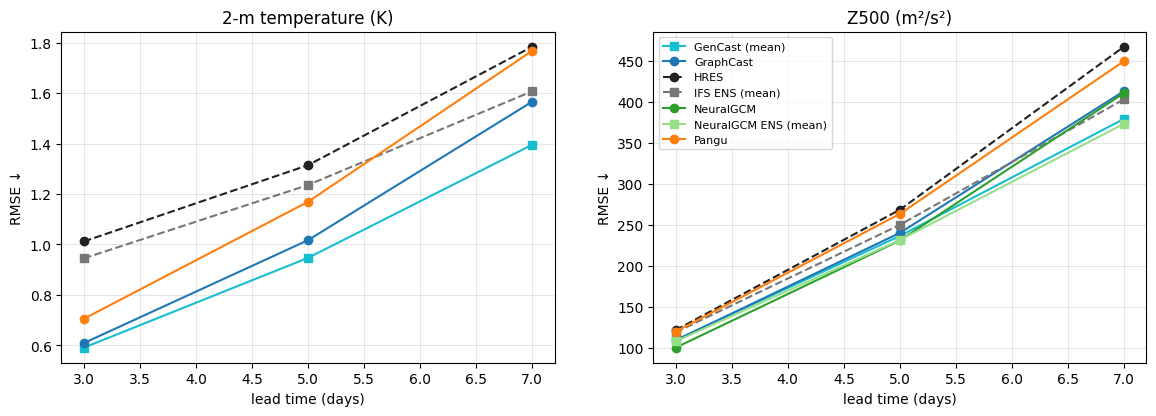

model                GenCast (mean)  GraphCast    HRES  IFS ENS (mean)  \
var            days                                                      
2m_temperature 3               0.59       0.61    1.01            0.94   
               5               0.95       1.02    1.31            1.24   
               7               1.40       1.57    1.78            1.61   
geopotential   3             109.70     109.25  121.81          119.17   
               5             236.48     240.21  268.42          250.00   
               7             379.17     412.96  467.08          402.97   

model                NeuralGCM  NeuralGCM ENS (mean)   Pangu  
var            days                                           
2m_temperature 3           NaN                   NaN    0.71  
               5           NaN                   NaN    1.17  
               7           NaN                   NaN    1.77  
geopotential   3        100.43                108.03  120.02  
               5        231.00                231.56  263.31  
               7        410.61                373.23  449.48

In [6]:
rows = []
for var in ['2m_temperature', 'geopotential']:
    for d, l in LEADS.items():
        for m in DET:
            fc, tr = det_forecast(m, var, l)
            if fc is not None: rows.append({'model': m, 'var': var, 'days': d, 'rmse': rmse(fc, tr)})
        for m, (n, md) in ENS.items():
            fc, tr = ens_forecast(m, var, l, 50)
            if fc is not None: rows.append({'model': m + ' (mean)', 'var': var, 'days': d, 'rmse': rmse(fc.mean(md), tr)})
cmp_ = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3))
for a, var in zip(axs, ['2m_temperature', 'geopotential']):
    for m, s in cmp_[cmp_['var'] == var].groupby('model'):
        a.plot(s.days, s.rmse, marker='s' if 'mean' in m else 'o', ls=STYLE[m.replace(' (mean)', '')], color=col(m), label=m)
    a.set_title(VARS[var]); a.set_xlabel('lead time (days)'); a.set_ylabel('RMSE ↓'); a.grid(alpha=.3)
axs[1].legend(fontsize=8)
save(fig, '2.5')
cmp_.pivot_table(index=['var', 'days'], columns='model', values='rmse').round(2)

### Figure 2.6 · One city: two ensembles

*How to read:* Five-day forecasts of 2-m temperature for one grid box. Shaded = range of the middle 90 % of members, line = ensemble mean, black = what happened. Ideal: reality outside the shaded range about 10 % of the time.

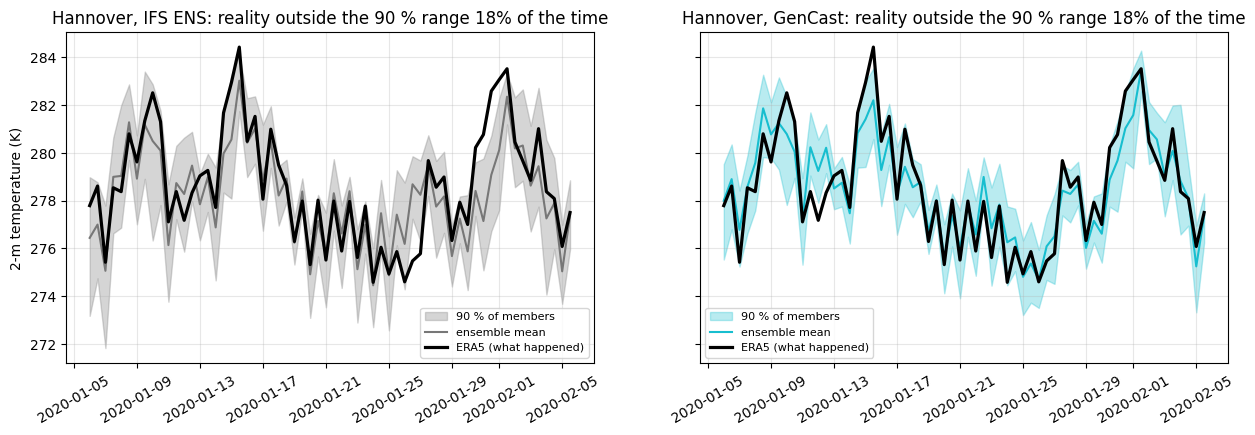

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for a, m in zip(axs, ['IFS ENS', 'GenCast']):
    n, md = ENS[m]
    fc, tr = ens_forecast(m, '2m_temperature', LEADS[5], 50)
    p, pt = point(fc, CITY), point(tr, CITY)
    lo, hi = p.quantile(.05, md), p.quantile(.95, md)
    share = float(((pt < lo) | (pt > hi)).mean())
    a.fill_between(p.time.values, lo, hi, color=COLORS[m], alpha=.3, label='90 % of members')
    a.plot(p.time, p.mean(md), color=COLORS[m], lw=1.5, label='ensemble mean')
    a.plot(pt.time, pt, 'k', lw=2.3, label='ERA5 (what happened)')
    a.set_title(f'{CITY}, {m}: reality outside the 90 % range {share:.0%} of the time'); a.grid(alpha=.3); a.legend(fontsize=8)
    a.tick_params(axis='x', rotation=30)
axs[0].set_ylabel('2-m temperature (K)')
save(fig, '2.6')

### Figure 2.7 · Where the ensembles are unsure, and where they are wrong

*How to read:* Top: ensemble spread (how unsure the model is). Bottom: error of the ensemble mean (how wrong it was). Z500, day 5, same colour scale everywhere.

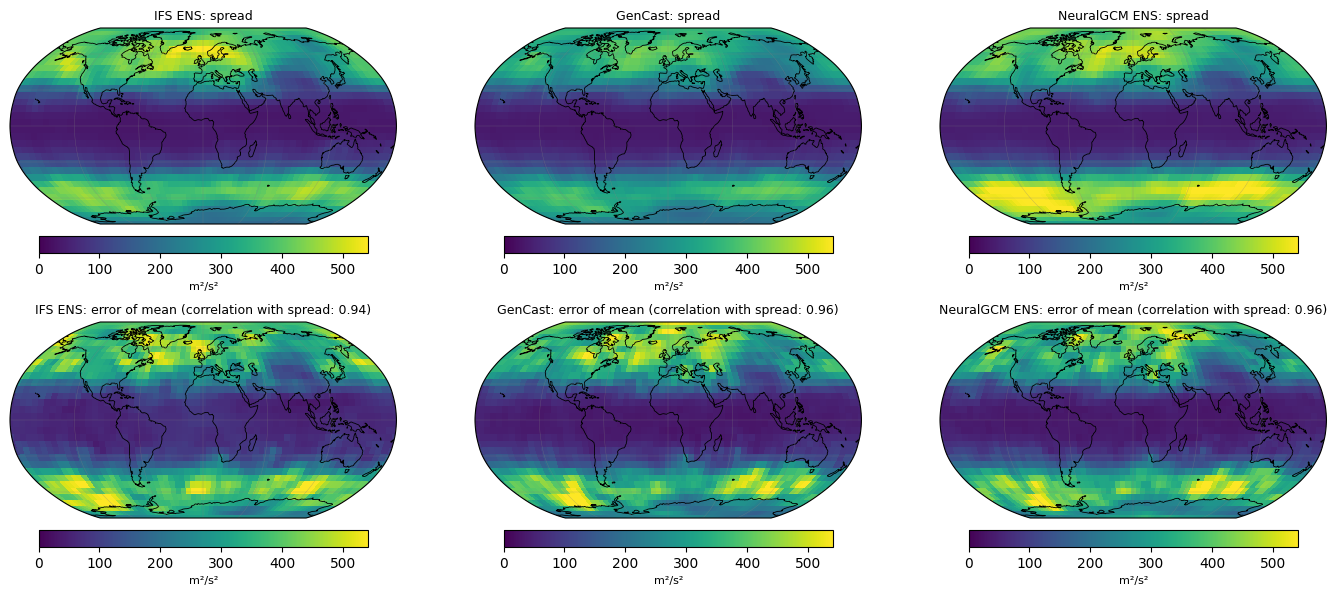

In [8]:
fields = {}
for m in ['IFS ENS', 'GenCast', 'NeuralGCM ENS']:
    n, md = ENS[m]
    fc, tr = ens_forecast(m, 'geopotential', LEADS[5], 50)
    fields[m] = (np.sqrt(fc.var(md).mean('time')), np.sqrt(((fc.mean(md) - tr) ** 2).mean('time')))
v = float(max(max(s.quantile(.98), e.quantile(.98)) for s, e in fields.values()))
fig, axs = map_subplots(2, 3, figsize=(17, 7))
for j, (m, (s, e)) in enumerate(fields.items()):
    r = float(xr.corr(s, e))
    plot_map(axs[0, j], s, f'{m}: spread', 'viridis', 0, v, 'm²/s²')
    plot_map(axs[1, j], e, f'{m}: error of mean (correlation with spread: {r:.2f})', 'viridis', 0, v, 'm²/s²')
save(fig, '2.7')